![Banner](../images/09_08_banner_rs_super_resolution.png)


# PlanetScope to high-resolution NAIP-style imagery: super-resolution

This tutorial follows the workflow of `07_07_01_Landsat8_to_Sentinel2_Super_Resolution.ipynb`, using the provided **PlanetScope July 14, 2019** image at 3 m as the coarse input and `HR_Rural_AOI_July_14.tif` at 0.6 m as the fine reference.


## Overview

The PlanetScope Explorer manifest identifies scene `20190714_142708_1049`, acquired 2019-07-14 14:27:08 UTC. The high-resolution TIFF is dated July 14 in its filename, but its sidecar does not provide an acquisition timestamp; exact temporal coincidence therefore cannot be confirmed.

The comparison uses four bands: **blue, green, red, and NIR**. The PlanetScope AOI TIFF has generic band descriptions, so its PlanetScope PSScene 4-band order is assumed to be blue/green/red/NIR. The HR image also has generic labels; this notebook assumes the common NAIP-style order red/green/blue/NIR and reorders it to match PlanetScope. Verify this against the source product documentation before interpreting bands. PlanetScope integer values are divided by 10,000 as an explicit reflectance-like scaling assumption; the sidecar of the clipped TIFF does not record its scale. HR values are normalized from the apparent 8-bit range by dividing by 255, then calibrated **per band using training-area samples only** to match PlanetScope's coarse radiometry. This prevents a gross scale mismatch but does not make the sensors spectrally equivalent.

To keep the example reproducible and memory-conscious, it uses a 256×256-pixel PlanetScope window (about 768 m square), not the full AOI. GeoLattice compares nearest, bilinear, bicubic, Lanczos, and unsharp interpolation with an EDSR-style CNN. Spatially separated patches are held out. Scores measure agreement with this one high-resolution reference after training-only calibration-not absolute accuracy or proof of recovered native detail. A 0.6 m output grid does not mean PlanetScope measured 0.6 m detail.


## Workflow and GeoLattice functions

1. Read the PlanetScope July 14 AOI image and the high-resolution July 14 AOI image with `geolattice.rsense.read`.
2. Select a manageable PlanetScope window, create a 0.6 m GeoLattice output grid, and reproject/align the HR reference to it.
3. Build valid-data masks and fit a simple per-band radiometric mapping from training regions only.
4. Compare classical interpolation methods, train an EDSR-style CNN on paired patches, and evaluate on spatially held-out patches.
5. Export the masked estimates as georeferenced Cloud-Optimized GeoTIFFs using `geolattice.rsense.write`.

The PlanetScope-to-HR spacing ratio is 3.0/0.6 = **5**. GeoLattice provides the interpolation, model, tiled inference, and raster I/O; PyTorch is needed for the CNN (`pip install "geolattice[rsense-dl]"`).


### Imports, paths, and experiment settings

This cell imports GeoLattice for georeferenced raster operations, NumPy/PyTorch for model training, and plotting tools. It finds the repository so the notebook can use the current source checkout when available. The file paths use the supplied July 14 PlanetScope and HR AOI rasters. The band order and scaling settings are explicitly visible assumptions. `WINDOW_ROW` and `WINDOW_COL` select a 256×256 PlanetScope region; this makes the HR reprojection and model inference practical on a typical workstation.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
from pathlib import Path  # file paths
import json  # read the PlanetScope metadata JSON
import os  # environment variables and CPU count
import sys  # Python import path

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import torch  # PyTorch: the neural super-resolution model
import xarray as xr  # labelled arrays and result tables
from rasterio.enums import Resampling  # resampling methods
from scipy.ndimage import distance_transform_edt  # distance to the nearest valid pixel (gap filling)
from torch.utils.data import DataLoader, TensorDataset  # feed patches to PyTorch in batches

# Prefer this repository's current GeoLattice source when the notebook runs in the checkout.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import super_resolution as sr  # super-resolution tools

if ROOT is None:  # not started inside the repository
    # stop with a clear message
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_08_image_super_resolution"
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_08_image_super_resolution"  # its data folder
PLANET_DIR = DATA_DIR / "Planet" / "July_14_2019"  # PlanetScope folder (14 July 2019)
HR_DIR = DATA_DIR / "HR"  # high-resolution (HR) image folder
PLANET_PATH = PLANET_DIR / "Planet_Rural_AOI_July_14_2019_NAD.tif"  # the PlanetScope image
HR_PATH = HR_DIR / "HR_Rural_AOI_July_14.tif"  # the HR image
# PlanetScope order manifest
PLANET_MANIFEST = PLANET_DIR / "Rural_July_14_2019_PSScene4Band_Explorer" / "manifest.json"
# Every input is a prepared clip of the study area kept in data/; there is no public download
# for these clips, so stop with a clear message when one is missing from the local drive.
INPUTS = [PLANET_PATH, HR_PATH]  # the input rasters of this notebook
missing = [str(p) for p in INPUTS if not p.exists()]  # inputs not found on the local drive
if missing:  # stop early with the list of missing files
    raise FileNotFoundError("Copy these files into the data folder first: " + ", ".join(missing))
print("Reading", len(INPUTS), "input rasters from", DATA_DIR)  # all inputs are local

OUTPUT_DIR = Path(os.environ.get(  # output folder (can be changed with an environment variable)
    "GEOLATTICE_SR_OUTPUT", DATA_DIR / "super_resolution_outputs_planet_to_hr"
))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

BANDS = ["blue", "green", "red", "nir"]  # the four bands both images share
PLANET_DN_TO_REFLECTANCE = 1e-4  # Explicit assumption; verify against original clipped-product metadata.
HR_DN_TO_UNIT_RANGE = 1 / 255  # HR pixels range to approximately 0..255; verify source encoding.
SCALE = 5  # 3 m PlanetScope -> 0.6 m: 5 times finer
WINDOW_ROW, WINDOW_COL = 500, 500  # top-left corner of the study window (PlanetScope pixels)
WINDOW_SIZE = 256  # window size: 256 x 256 PlanetScope pixels
PATCH = 16  # PlanetScope pixels; target patch width is 80 HR pixels.
SEED = 14  # random seed
torch.manual_seed(SEED)  # same initial weights on every run
torch.set_num_threads(min(4, os.cpu_count() or 1))  # use at most four CPU threads
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # use the GPU when available
print("GeoLattice checkout:", ROOT)  # repository path
print("PyTorch:", torch.__version__, "| device:", DEVICE)  # PyTorch version and device
print("Output folder:", OUTPUT_DIR)  # output folder
print("PlanetScope scale assumption:", PLANET_DN_TO_REFLECTANCE,  # the assumed scale factors
      "| HR unit-range assumption:", HR_DN_TO_UNIT_RANGE)

GeoLattice checkout: /media/zia207/SSD/GitHub/GeoLattice
PyTorch: 2.10.0+cu128 | device: cuda
Output folder: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr
PlanetScope scale assumption: 0.0001 | HR unit-range assumption: 0.00392156862745098


### Inspect product metadata and read the PlanetScope window

The Explorer manifest supplies the original PlanetScope item ID and acquisition time; it does not by itself guarantee that the clipped AOI TIFF preserves those original radiometric values unchanged. The AOI TIFF's band descriptions are generic, so band order remains an assumption. `rs.read` masks the file's nodata value. We select only a 256×256 window, scale its integer values, and retain the spatial coordinates and transform for downstream georeferencing.


In [2]:
manifest = json.loads(PLANET_MANIFEST.read_text())  # the PlanetScope manifest
planet_item_path = next(  # path of the scene's metadata JSON inside the order
    entry["path"] for entry in manifest["files"]
    if entry["path"].endswith("20190714_142708_1049_metadata.json")
)
explorer_dir = PLANET_DIR / "Rural_July_14_2019_PSScene4Band_Explorer"  # folder of the order
planet_item = json.loads((explorer_dir / planet_item_path).read_text())  # the scene metadata
planet_properties = planet_item["properties"]  # its properties

# PlanetScope PSScene4Band channel order is assumed to be blue, green, red, NIR.
planet_all = rs.read(PLANET_PATH, band_names=BANDS)
planet_window_dn = planet_all.isel(  # the study window of the PlanetScope image
    y=slice(WINDOW_ROW, WINDOW_ROW + WINDOW_SIZE),
    x=slice(WINDOW_COL, WINDOW_COL + WINDOW_SIZE),
)
# DN -> reflectance with the assumed scale factor
planet_low = planet_window_dn.astype("float32") * PLANET_DN_TO_REFLECTANCE
planet_values = np.asarray(planet_low.values, dtype="float32")  # as a float array
planet_valid = np.isfinite(planet_values).all(axis=0)  # finite in every band

print("Planet item:", planet_item["id"], planet_properties["item_type"])  # scene ID and product type
print("Planet acquired:", planet_properties["acquired"])  # acquisition time
# instrument and ground sample distance
print("Planet instrument/GSD:", planet_properties["instrument"], planet_properties["gsd"], "m")
# shape, CRS and resolution of the full AOI
print("Planet AOI shape/CRS/resolution:", planet_all.shape, planet_all.rio.crs,
      planet_all.rio.resolution())
print("Selected window shape/bounds:", planet_low.shape, planet_low.rio.bounds())  # window shape and bounds
print("Valid PlanetScope pixels:", f"{planet_valid.mean():.1%}")  # valid share
print("Window value percentiles by assumed band:",  # value percentiles of each band
      np.nanpercentile(planet_values, [1, 50, 99], axis=(1, 2)))

Planet item: 20190714_142708_1049 PSScene4Band
Planet acquired: 2019-07-14T14:27:08.594337Z
Planet instrument/GSD: PS2 3.6 m
Planet AOI shape/CRS/resolution: (4, 2153, 2022) EPSG:26918 (3.0, -3.0)
Selected window shape/bounds: (4, 256, 256) (257871.20228942018, 4745783.0456366595, 258639.20228942018, 4746551.0456366595)
Valid PlanetScope pixels: 100.0%
Window value percentiles by assumed band: [[0.0251     0.0324     0.0241     0.23549999]
 [0.0404     0.0524     0.0418     0.36769998]
 [0.0949     0.1036     0.1038     0.5431    ]]


### Align the HR reference to the exact 0.6 m output grid

The PlanetScope AOI raster has 3 m pixels and the HR AOI raster has 0.6 m pixels. `sr.upsample` creates the exact five-times output grid. The HR source is read lazily in chunks and clipped to that small grid's bounds before reprojection, avoiding a full-scene HR load. The HR file's band labels are generic; this example assumes the common RGB/NIR order and reorders those channels to PlanetScope's B/G/R/NIR order. Bilinear reprojection corrects the slight difference in grid origin while retaining the high-resolution reference. The operation does not establish that either sensor's spectra are calibrated to the other.


In [3]:
# the 0.6 m target grid (bicubic template from PlanetScope)
planet_grid = sr.upsample(planet_low, SCALE, method="bicubic")

# HR source assumed order is red, green, blue, NIR; reorder to blue, green, red, NIR.
hr_source = rs.read(
    HR_PATH,
    chunks={"x": 2048, "y": 2048},
    band_names=["red", "green", "blue", "nir"],
)
# reorder the HR bands to blue, green, red, NIR
hr_bgrn = hr_source.isel(band=[2, 1, 0, 3]).assign_coords(band=BANDS)
hr_unit = hr_bgrn.astype("float32") * HR_DN_TO_UNIT_RANGE  # HR DN -> 0-1 range

xmin, ymin, xmax, ymax = planet_grid.rio.bounds()  # extent of the target grid
hr_subset = hr_unit.rio.clip_box(minx=xmin, miny=ymin, maxx=xmax, maxy=ymax)  # clip the HR image to it
hr_reference = hr_subset.rio.reproject_match(  # align the HR image exactly to the target grid
    planet_grid, resampling=Resampling.bilinear
).assign_coords(band=BANDS)
hr_reference = hr_reference.rio.write_nodata(np.nan)  # NaN marks no data
hr_values = np.asarray(hr_reference.values, dtype="float32")  # as a float array
hr_valid = np.isfinite(hr_values).all(axis=0)  # finite in every band

assert hr_reference.shape == planet_grid.shape  # same shape as the target grid
assert hr_reference.rio.crs == planet_grid.rio.crs  # same CRS
assert np.allclose(hr_reference.rio.transform(), planet_grid.rio.transform())  # same transform
print("Planet low-resolution grid:", planet_low.rio.crs,  # PlanetScope grid
      planet_low.rio.resolution(), planet_low.rio.bounds())
print("Matched HR reference grid:", hr_reference.shape,  # matched HR grid
      hr_reference.rio.resolution(), hr_reference.rio.bounds())
print("HR valid fraction:", f"{hr_valid.mean():.1%}")  # valid HR share

Planet low-resolution grid: EPSG:26918 (3.0, -3.0) (257871.20228942018, 4745783.0456366595, 258639.20228942018, 4746551.0456366595)
Matched HR reference grid: (4, 1280, 1280) (0.6000000000000182, -0.6000000000002913) (257871.20228942018, 4745783.0456366595, 258639.20228942018, 4746551.0456366595)
HR valid fraction: 100.0%


### Create valid overlap and temporarily fill input gaps

The PlanetScope mask comes from its nodata value; the HR mask comes from its own nodata value after alignment. The shared high-resolution mask also requires the corresponding PlanetScope input pixel to be valid. Nearest-neighbor filling is only for finite-valued model/interpolation inputs. Those temporary fills are excluded from training, held-out scores, and exported products.


In [4]:
planet_valid_hr = np.asarray(  # PlanetScope validity on the 0.6 m grid (nearest neighbour)
    sr.upsample(
        planet_low.isel(band=0, drop=True).copy(data=planet_valid.astype("float32")),
        SCALE,
        method="nearest",
    ).values > 0.5
)
valid_pair_hr = planet_valid_hr & hr_valid  # pixels valid in both on the 0.6 m grid
if not planet_valid.any() or not hr_valid.any() or not valid_pair_hr.any():  # nothing valid
    raise ValueError("The selected PlanetScope/HR window has no valid overlap")  # stop with a clear message

def fill_invalid_nearest(cube, valid):  # fill invalid pixels with the nearest valid value
    """Temporarily fill invalid (band, y, x) values from their nearest valid pixel."""
    if not valid.any():  # nothing to fill from
        raise ValueError("Cannot fill an image with no valid pixels")  # stop with a clear message
    # row and column of the nearest valid pixel
    rows, cols = distance_transform_edt(~valid, return_distances=False, return_indices=True)
    filled = np.asarray(cube, dtype="float32").copy()  # copy of the cube
    for band in range(filled.shape[0]):  # every band
        filled[band, ~valid] = filled[band, rows[~valid], cols[~valid]]  # copy the nearest valid value
    return filled  # the filled cube

planet_filled = fill_invalid_nearest(planet_values, planet_valid)  # PlanetScope with gaps filled
hr_filled = fill_invalid_nearest(hr_values, hr_valid)  # HR with gaps filled
planet_filled_da = planet_low.copy(data=planet_filled)  # filled PlanetScope as a georeferenced DataArray
print("PlanetScope valid:", f"{planet_valid.mean():.1%}",  # valid shares
      "| HR valid:", f"{hr_valid.mean():.1%}",
      "| valid paired output:", f"{valid_pair_hr.mean():.1%}")

PlanetScope valid: 100.0% | HR valid: 100.0% | valid paired output: 100.0%


### Display both images with independent RGB stretches

The two products use different radiometric scales: PlanetScope is converted from integer values using the assumed 0.0001 factor, while HR values are normalized from an 8-bit-like range. A shared display stretch therefore makes PlanetScope appear nearly black. This visualization helper computes separate 2nd-98th percentile stretches for each image, using only valid pixels. Independent stretches improve visibility but do not support direct color or reflectance comparison; the separate calibration and evaluation steps remain unchanged.


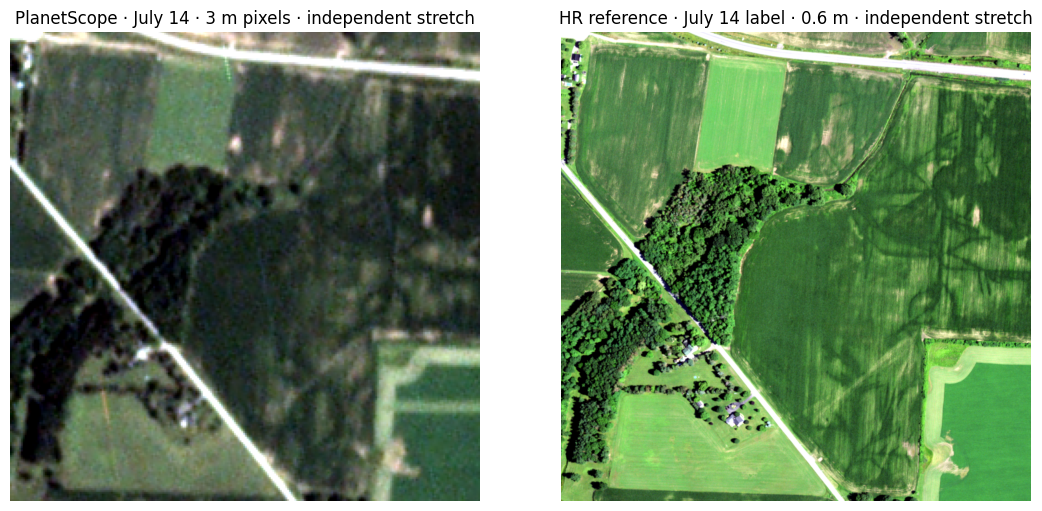

In [5]:
def rgb_stretch(cube, valid, bands=(2, 1, 0), percentiles=(2, 98)):  # contrast-stretched RGB image of a cube
    """Return an independently contrast-stretched display RGB image."""
    rgb = cube[list(bands)].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for channel in range(3):  # each colour channel
        values = rgb[..., channel][keep]  # its valid values
        if values.size == 0:  # nothing to stretch
            # stop with a clear message
            raise ValueError("No valid pixels are available for the RGB display stretch")
        low, high = np.percentile(values, percentiles)  # percentile limits
        rgb[..., channel] = np.clip(  # stretch to [0, 1]
            (rgb[..., channel] - low) / max(high - low, 1e-6), 0, 1
        )
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)  # two panels
axes[0].imshow(rgb_stretch(planet_filled, planet_valid))  # PlanetScope
axes[0].set_title("PlanetScope · July 14 · 3 m pixels · independent stretch")  # title
axes[1].imshow(rgb_stretch(hr_filled, valid_pair_hr))  # HR image
axes[1].set_title("HR reference · July 14 label · 0.6 m · independent stretch")  # title
for ax in axes:  # for both panels
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Classical methods

### Run GeoLattice interpolation and unsharp masking

GeoLattice `upsample` creates nearest, bilinear, bicubic, and Lanczos outputs on the five-times 0.6 m grid. `unsharp_mask` adds local contrast to bicubic output. These are baselines made solely from PlanetScope samples; they cannot uniquely reconstruct the finer structures in the reference image. The HR image is not used to create these classical outputs.


In [6]:
classical_da = {  # four interpolation methods to the 0.6 m grid
    "Nearest": sr.upsample(planet_filled_da, SCALE, method="nearest"),
    "Bilinear": sr.upsample(planet_filled_da, SCALE, method="bilinear"),
    "Bicubic": sr.upsample(planet_filled_da, SCALE, method="bicubic"),
    "Lanczos": sr.upsample(planet_filled_da, SCALE, method="lanczos"),
}
classical = {name: np.asarray(image.values, dtype="float32")  # their values as arrays
             for name, image in classical_da.items()}
classical["Unsharp bicubic"] = sr.unsharp_mask(  # mild sharpening of the bicubic result
    classical["Bicubic"], amount=0.5, sigma=1.0
)
assert all(cube.shape == hr_values.shape for cube in classical.values())  # all have the HR shape
print({name: cube.shape for name, cube in classical.items()})  # their shapes

{'Nearest': (4, 1280, 1280), 'Bilinear': (4, 1280, 1280), 'Bicubic': (4, 1280, 1280), 'Lanczos': (4, 1280, 1280), 'Unsharp bicubic': (4, 1280, 1280)}


## Deep learning: paired multispectral EDSR-style CNN

### Split paired patches spatially and calibrate HR on training areas

Each 16×16 PlanetScope patch is paired with an 80×80 HR patch. A deterministic block split keeps adjacent patches in the same partition. Only valid patches with at least 98% clear coverage are used. Before training, the HR values (normalized from their 8-bit-like range) are pooled into 5×5 blocks and a separate linear radiometric transform is fitted for each band using **training patches only**. Applying that transform to the HR reference makes its coarse radiometry approximately match PlanetScope while retaining the sub-pixel pattern. This is a simple empirical adjustment-not atmospheric correction or sensor harmonization-and scores later use the calibrated HR reference.


In [7]:
PATCH_HR = PATCH * SCALE  # size of a target patch on the 0.6 m grid
low_height, low_width = planet_valid.shape  # PlanetScope window size
patch_records = []  # usable patches: position and validation flag
for row in range(0, low_height - PATCH + 1, PATCH):  # patch rows
    for col in range(0, low_width - PATCH + 1, PATCH):  # patch columns
        low_mask = planet_valid[row:row + PATCH, col:col + PATCH]  # PlanetScope validity of the patch
        fine_row, fine_col = row * SCALE, col * SCALE  # matching position on the 0.6 m grid
        high_mask = valid_pair_hr[  # validity of the matching 0.6 m patch
            fine_row:fine_row + PATCH_HR, fine_col:fine_col + PATCH_HR
        ]
        if low_mask.mean() >= 0.98 and high_mask.mean() >= 0.98:  # keep patches at least 98 % valid in both
            tile_row, tile_col = row // PATCH, col // PATCH  # patch row and column number
            # every fifth 2 x 2 block of patches is held out
            validation = ((tile_row // 2 + tile_col // 2) % 5) == 0
            patch_records.append((row, col, validation))  # store the patch

train_records = [record for record in patch_records if not record[2]]  # training patches
validation_records = [record for record in patch_records if record[2]]  # validation patches
if len(train_records) < 8 or len(validation_records) < 2:  # too few of either
    # stop with a clear message
    raise RuntimeError(f"Too few valid paired patches: {len(train_records)} train, "
                       f"{len(validation_records)} validation")

# Aggregate the aligned 0.6 m HR reference into exact 3 m blocks for radiometric fitting.
hr_sum = np.where(np.isfinite(hr_values), hr_values, 0).reshape(
    4, low_height, SCALE, low_width, SCALE
).sum(axis=(2, 4))
hr_count = np.isfinite(hr_values).all(axis=0).reshape(  # valid HR pixels in each 5 x 5 block
    low_height, SCALE, low_width, SCALE
).sum(axis=(1, 3))
hr_coarse = hr_sum / np.maximum(hr_count[None, :, :], 1)  # mean HR value of each 3 m block
train_area = np.zeros((low_height, low_width), dtype=bool)  # mask of the training patches
for row, col, _ in train_records:  # every training patch
    train_area[row:row + PATCH, col:col + PATCH] = True  # mark it
# fit only on training pixels with complete blocks
calibration_mask = train_area & planet_valid & (hr_count >= SCALE * SCALE * 0.98)

calibration = []  # (slope, intercept) per band
for band in range(len(BANDS)):  # every band
    # Fit HR_unit * slope + intercept ~= PlanetScope reflectance on train pixels only.
    slope, intercept = np.polyfit(
        hr_coarse[band][calibration_mask], planet_values[band][calibration_mask], 1
    )
    calibration.append((float(slope), float(intercept)))  # store the fit
hr_calibrated = np.asarray([  # the HR image converted to the PlanetScope scale
    hr_filled[b] * calibration[b][0] + calibration[b][1]
    for b in range(len(BANDS))
], dtype="float32")

print(f"Paired patches: {len(patch_records)} total; {len(train_records)} training; "  # patch counts
      f"{len(validation_records)} spatial holdout")
print("Train-only HR-to-Planet calibration (slope, intercept):")  # heading
for band, coefficients in zip(BANDS, calibration):  # every band
    print(f"  {band}: {coefficients}")  # its slope and intercept
print("Patch tensors will be:", (len(train_records), len(BANDS), PATCH, PATCH),  # tensor shapes that follow
      "to", (len(train_records), len(BANDS), PATCH_HR, PATCH_HR))

Paired patches: 256 total; 208 training; 48 spatial holdout
Train-only HR-to-Planet calibration (slope, intercept):
  blue: (0.13517593065605168, 0.00836017859982146)
  green: (0.11701612685330663, 0.01132020489574843)
  red: (0.12292360754423903, 0.012634666852824246)
  nir: (0.6625593071764497, -0.057581205567209144)
Patch tensors will be: (208, 4, 16, 16) to (208, 4, 80, 80)


### Prepare tensors, build the GeoLattice model, and train

Training tensors contain PlanetScope input patches and the radiometrically adjusted HR targets. The EDSR-style model predicts four bands at ×5 scale. GeoLattice training combines reflectance L1, spectral-angle, and coarse-observation consistency losses. The latter discourages predictions that contradict PlanetScope but cannot determine the unique fine detail. A single 768 m window provides a teaching example, not enough independent geography for a robust operational model.


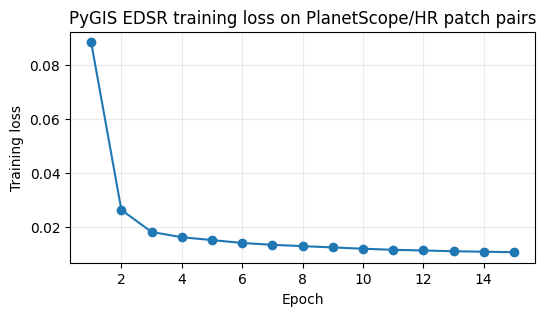

In [8]:
X_train = torch.from_numpy(np.stack([  # training inputs: PlanetScope patches
    planet_filled[:, row:row + PATCH, col:col + PATCH]
    for row, col, _ in train_records
])).float()
Y_train = torch.from_numpy(np.stack([  # training targets: calibrated HR patches
    hr_calibrated[:, row * SCALE:(row + PATCH) * SCALE,
                  col * SCALE:(col + PATCH) * SCALE]
    for row, col, _ in train_records
])).float()
# shuffled batches of 8 patches
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=8, shuffle=True)

model = sr.build_sr_model(  # an EDSR network with 24 features and 3 residual blocks, upscaling by 5
    in_channels=len(BANDS), scale=SCALE, features=24, blocks=3, architecture="edsr"
)
history = sr.train_super_resolution(  # train it for 15 epochs
    model, train_loader, epochs=15, lr=1e-4, device=DEVICE,
    sam_weight=0.05, consistency_weight=0.05,
)

fig, ax = plt.subplots(figsize=(6, 3))  # one panel
# training loss per epoch
ax.plot(np.arange(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o")
ax.set(xlabel="Epoch", ylabel="Training loss",  # labels and title
       title="GeoLattice EDSR training loss on PlanetScope/HR patch pairs")
ax.grid(alpha=0.25)  # grid
plt.show()  # draw

## Inference and held-out evaluation

### Tiled prediction and spatial holdout metrics

`predict_super_resolution` processes the PlanetScope window in overlapping tiles and blends predictions to reduce seams. For a georeferenced xarray input, the returned image keeps the 0.6 m grid metadata. Held-out RMSE, PSNR, and SAM are computed only over validation patches with valid overlap; the reference is the HR image after applying the training-only per-band adjustment. These are within-window diagnostic metrics. They are affected by the assumed bands/scales, the unknown HR capture time, residual registration error, and the difference between sensor spectral responses.


In [9]:
neural_da = sr.predict_super_resolution(  # apply the network to the whole PlanetScope window
    model, planet_filled_da, tile=64, overlap=12, batch_size=4, device=DEVICE
)
neural = np.asarray(neural_da.values, dtype="float32")  # the prediction as an array
assert neural.shape == hr_values.shape  # same shape as the reference
candidates = {**classical, "CNN (paired patches)": neural}  # classical estimates plus the network

def heldout_metrics(prediction):  # scores on the held-out patches only
    """Compute RMSE, PSNR (unit reflectance range), and SAM on held-out patches."""
    estimates, references = [], []  # pieces of prediction and reference
    for row, col, _ in validation_records:  # every validation patch
        r0, c0 = row * SCALE, col * SCALE  # its position on the 0.6 m grid
        mask = valid_pair_hr[r0:r0 + PATCH_HR, c0:c0 + PATCH_HR]  # valid pixels of the patch
        if mask.any():  # skip patches without valid pixels
            # the predicted patch, valid pixels only
            estimates.append(prediction[:, r0:r0 + PATCH_HR, c0:c0 + PATCH_HR][:, mask])
            references.append(hr_calibrated[:, r0:r0 + PATCH_HR,  # the reference patch, valid pixels only
                                            c0:c0 + PATCH_HR][:, mask])
    if not estimates:  # nothing to score
        raise ValueError("No valid validation pixels are available")  # stop with a clear message
    estimate = np.concatenate(estimates, axis=1)  # all prediction pixels
    reference = np.concatenate(references, axis=1)  # all reference pixels
    rmse = float(np.sqrt(np.mean((estimate - reference) ** 2)))  # root-mean-square error
    dot = np.sum(estimate * reference, axis=0)  # dot product of the spectra
    norms = np.linalg.norm(estimate, axis=0) * np.linalg.norm(reference, axis=0)  # product of their lengths
    sam = np.degrees(np.arccos(np.clip(dot / np.maximum(norms, 1e-8), -1, 1)))  # spectral angle of every pixel
    return {"RMSE": rmse,  # RMSE, PSNR and mean spectral angle
            "PSNR (range=1)": float(20 * np.log10(1 / max(rmse, 1e-12))),
            "SAM (degrees)": float(sam.mean())}

scores = {name: heldout_metrics(cube) for name, cube in candidates.items()}  # score every method
score_table = xr.Dataset({  # scores as a table
    metric: xr.DataArray([scores[name][metric] for name in scores], dims="method",
                         coords={"method": list(scores)})
    for metric in next(iter(scores.values()))
}).to_dataframe()
display(score_table.sort_values("RMSE").style.format("{:.4f}"))  # best method first

,RMSE,PSNR (range=1),SAM (degrees)
method,,,
CNN (paired patches),0.0211,33.4984,1.4288
Bilinear,0.0244,32.2574,1.7018
Bicubic,0.0247,32.1559,1.7263
Unsharp bicubic,0.0247,32.1419,1.7302
Nearest,0.0247,32.1326,1.7381
Lanczos,0.0253,31.9466,1.7422


### Compare reference and model estimates

The display panels share RGB limits estimated from valid HR reference pixels. The reference panel shows the calibrated HR target; other panels show the estimates. The mask hides cloud/nodata and invalid pixels. Since HR values have a training-derived per-band affine transform, displayed colors are for spatial comparison only and should not be interpreted as physical PlanetScope reflectance.


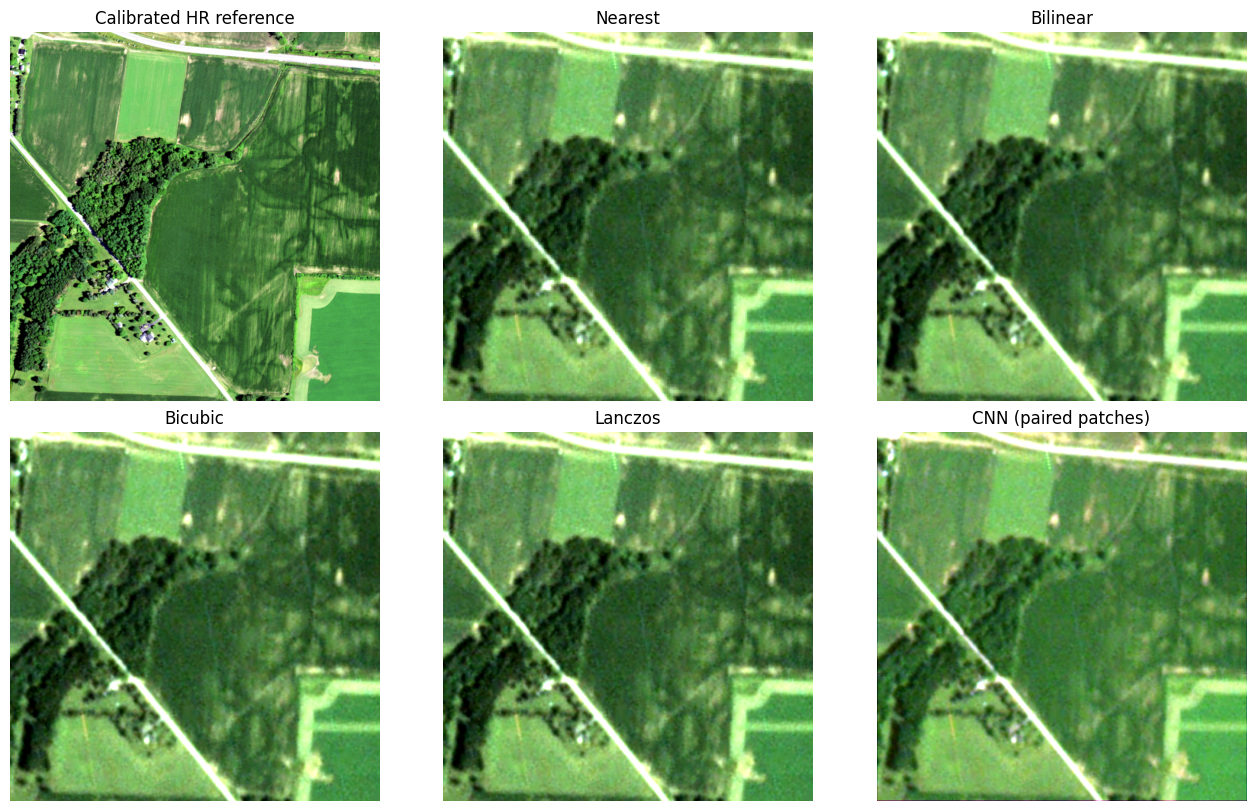

In [10]:
image_sets = {"Calibrated HR reference": hr_calibrated, **candidates}  # the reference plus every estimate
plot_order = ["Calibrated HR reference", "Nearest", "Bilinear", "Bicubic",  # panel order
              "Lanczos", "CNN (paired patches)"]

# These estimates share the PlanetScope-like scale after training-only calibration,
# so derive one comparison stretch from the calibrated HR reference.
reference_rgb = hr_calibrated[[2, 1, 0]].transpose(1, 2, 0)
comparison_mask = valid_pair_hr & np.isfinite(reference_rgb).all(axis=-1)  # valid pixels of the reference
comparison_limits = [  # 2-98 % limits of each channel, shared by all panels
    np.percentile(reference_rgb[..., channel][comparison_mask], [2, 98])
    for channel in range(3)
]

def rgb_comparison(cube, valid):  # RGB image with the shared stretch
    """Display model outputs with a common stretch for method-to-method comparison."""
    rgb = cube[[2, 1, 0]].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for channel, (low, high) in enumerate(comparison_limits):  # each channel with its limits
        rgb[..., channel] = np.clip(  # stretch to [0, 1]
            (rgb[..., channel] - low) / max(high - low, 1e-6), 0, 1
        )
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)  # 2 x 3 panels
for ax, name in zip(axes.flat, plot_order):  # one panel per image
    ax.imshow(rgb_comparison(image_sets[name], valid_pair_hr))  # RGB view
    ax.set_title(name)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Export georeferenced products with GeoLattice

### Write masked 0.6 m outputs

The bicubic xarray output provides the common 0.6 m transform, CRS, and band names. The original PlanetScope/HR overlap mask is restored before writing, so temporary fills are not exported as data. `rs.write` creates COGs. Each file represents a method-derived estimate at a 0.6 m grid; the EDSR output uses detail learned from the supplied HR image and training window.


In [11]:
template_hr = classical_da["Bicubic"]  # the bicubic result as template for the 0.6 m grid

def as_valid_georeferenced(cube, method_name):  # wrap an estimate as a georeferenced DataArray
    """Wrap estimates on the HR grid and restore invalid locations as nodata."""
    values = np.where(valid_pair_hr[None, :, :], cube, np.nan).astype("float32")  # invalid pixels -> NaN
    # the template with these values and NaN as no-data
    result = template_hr.copy(data=values).rio.write_nodata(np.nan)
    result.attrs = {  # record what the file contains
        "method": method_name,
        "coarse_source": PLANET_PATH.name,
        "fine_reference": HR_PATH.name,
        "planet_item_id": planet_item["id"],
        "planet_scale_assumption": PLANET_DN_TO_REFLECTANCE,
        "hr_scale_assumption": HR_DN_TO_UNIT_RANGE,
        "interpretation": "0.6 m output grid; estimated detail is not native PlanetScope measurement",
    }
    return result  # the DataArray

for name, cube in candidates.items():  # every estimate
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "")  # a file-safe name
    output_path = OUTPUT_DIR / f"{filename}.tif"  # output path
    rs.write(as_valid_georeferenced(cube, name), output_path, cog=True)  # save as a Cloud-Optimised GeoTIFF
    print("Wrote", output_path)  # report the file

Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/nearest.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/bilinear.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/bicubic.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/lanczos.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/unsharp_bicubic.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_planet_to_hr/cnn_paired_patches.tif


## Interpretation and limitations

- **Nearest, bilinear, bicubic, and Lanczos** are resampling baselines, not detail-recovery methods.
- **Unsharp masking** raises local contrast and may also amplify noise or introduce overshoot.
- **The EDSR-style CNN** learns a mapping from one PlanetScope/HR pair. Spatial holdout reduces local leakage, but it does not test transfer to another scene or geography.
- The PlanetScope AOI TIFF uses generic band names and has no explicit per-band scaling in its sidecar. This notebook assumes the PlanetScope PSScene 4-band order and divides integer values by 10,000; verify this against the source product metadata.
- The HR TIFF also has generic band labels. RGB/NIR order and division by 255 are assumptions; its exact acquisition timestamp and radiometric calibration are not documented in the supplied sidecar.
- Training-only per-band linear calibration reduces the coarse radiometric mismatch but does not harmonize spectral responses, atmospherically correct the HR image, or remove residual co-registration errors.
- PlanetScope's product has a 3 m pixel spacing and a reported 3.6 m GSD; NAIP-style HR pixels are 0.6 m. The network's 0.6 m grid is a prediction, not a PlanetScope measurement.

For research use, verify both source products' acquisition metadata, band ordering, radiometric scaling, and registration; repeat across multiple locations/dates; and evaluate downstream decisions independently. Label results as **model-derived estimates guided by the supplied HR reference**, not as native 0.6 m PlanetScope imagery.
